# Experiment 3: Breadth-first and depth-first search

A carved maze is searched by one function whose only switch is which end of
the frontier is popped (FIFO = BFS, LIFO = DFS).

In [1]:
import json
from collections import deque
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10})

## The maze: carved by randomized depth-first search
Odd-indexed cells are rooms; carving removes the wall between a room and an
unvisited neighbour. Every room is reachable, so a start-to-goal path exists.

In [2]:
def carve_maze(H=23, W=35, seed=7, extra=0.08):
    rng = np.random.default_rng(seed)
    maze = np.ones((H, W), dtype=int)                 # 1 = wall, 0 = open
    stack = [(1, 1)]; maze[1, 1] = 0
    while stack:
        r, c = stack[-1]
        nbrs = [(r+dr, c+dc, dr//2, dc//2) for dr, dc in ((-2,0),(2,0),(0,-2),(0,2))
                if 0 < r+dr < H-1 and 0 < c+dc < W-1 and maze[r+dr, c+dc] == 1]
        if not nbrs:
            stack.pop(); continue
        nr, nc, hr, hc = nbrs[rng.integers(len(nbrs))]
        maze[r+hr, c+hc] = 0; maze[nr, nc] = 0
        stack.append((nr, nc))
    # knock out a few extra walls so there is more than one route (loops)
    for r in range(1, H-1):
        for c in range(1, W-1):
            if maze[r, c] == 1 and rng.random() < extra:
                if (maze[r-1, c] == 0 and maze[r+1, c] == 0) or (maze[r, c-1] == 0 and maze[r, c+1] == 0):
                    maze[r, c] = 0
    return maze

maze = carve_maze()
H, W = maze.shape
START, GOAL = (1, 1), (H-2, W-2)
print(f'maze {H} x {W}, open cells {int((maze == 0).sum())}')

def neighbours(cell):
    r, c = cell
    for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):   # up, down, left, right
        nr, nc = r + dr, c + dc
        if 0 <= nr < H and 0 <= nc < W:                 # bounds first ...
            if maze[nr, nc] == 0:                       # ... then contents
                yield (nr, nc)

maze 23 x 35, open cells 395


## One function, two algorithms

In [3]:
def search(start, goal, mode='bfs'):
    frontier = deque([start])
    parent = {start: None}              # doubles as the 'seen' set
    order, frontier_size = {}, []
    while frontier:
        node = frontier.popleft() if mode == 'bfs' else frontier.pop()   # the only difference
        if node in order:
            continue
        order[node] = len(order)
        frontier_size.append(len(frontier))
        if node == goal:
            break
        for nxt in neighbours(node):
            if nxt not in parent:       # mark on enqueue, not on expansion
                parent[nxt] = node
                frontier.append(nxt)
    path, cur = [], goal
    if goal in parent:
        while cur is not None:
            path.append(cur); cur = parent[cur]
    return order, path[::-1], frontier_size

def validate(path):
    ok_adj = all(abs(a[0]-b[0]) + abs(a[1]-b[1]) == 1 for a, b in zip(path, path[1:]))
    ok_wall = all(maze[r, c] == 0 for r, c in path)
    return ok_adj and ok_wall and path[0] == START and path[-1] == GOAL

res = {}
for mode in ('bfs', 'dfs'):
    order, path, fsz = search(START, GOAL, mode)
    res[mode] = dict(expanded=len(order), path_cells=len(path), path_steps=len(path) - 1,
                     valid=validate(path), max_frontier=max(fsz))
    print(mode.upper(), res[mode])

BFS {'expanded': 395, 'path_cells': 65, 'path_steps': 64, 'valid': True, 'max_frontier': 16}
DFS {'expanded': 222, 'path_cells': 115, 'path_steps': 114, 'valid': True, 'max_frontier': 15}


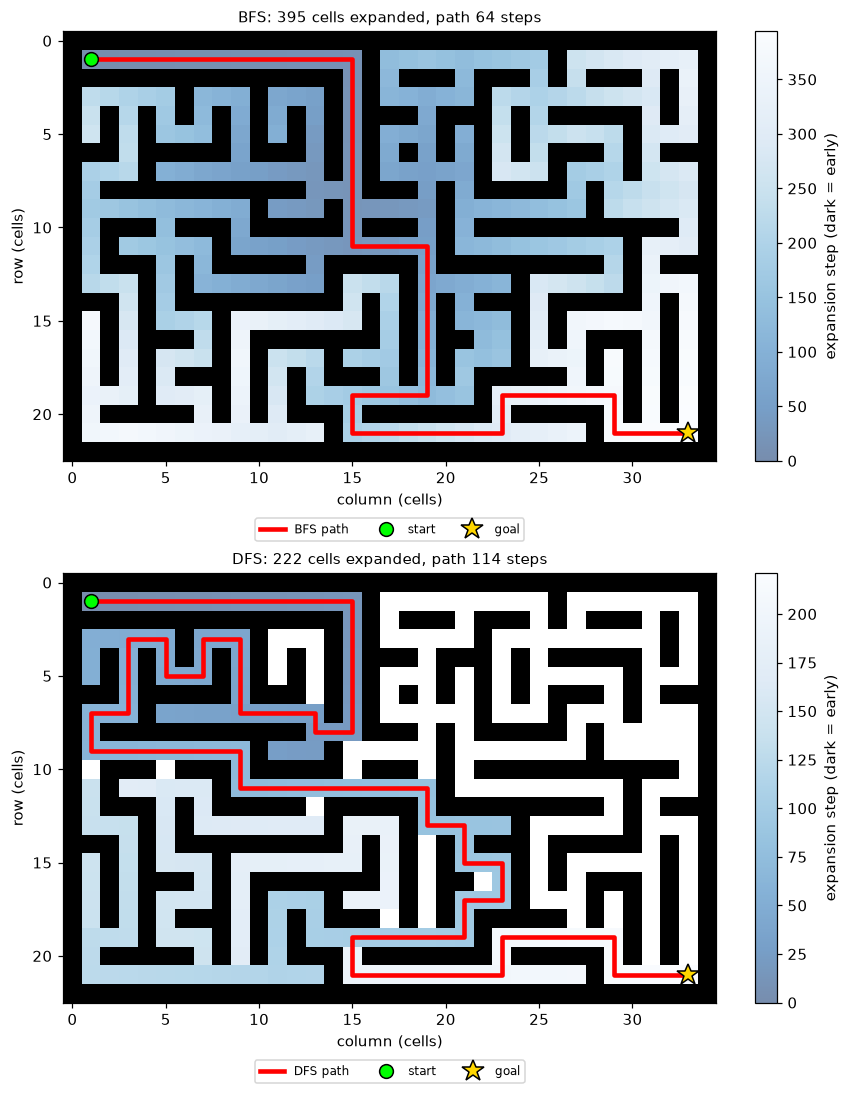

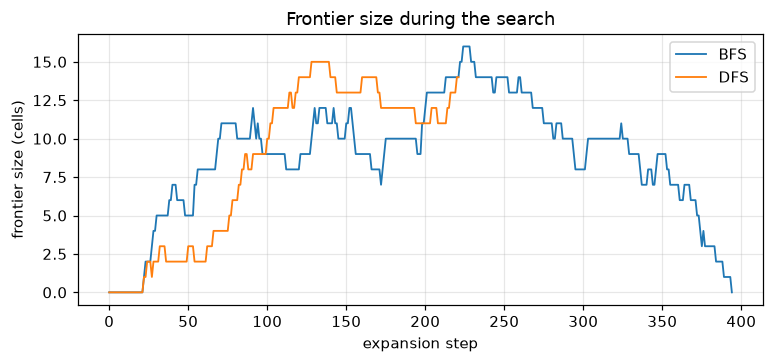

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(8, 10))
for ax, mode, col in zip(axes, ['bfs', 'dfs'], ['red', 'red']):
    order, path, _ = search(START, GOAL, mode)
    grid = np.full(maze.shape, np.nan)
    for (r, c), k in order.items():
        grid[r, c] = k
    ax.imshow(maze, cmap='binary', extent=(-0.5, W-0.5, H-0.5, -0.5))
    im = ax.imshow(grid, cmap='Blues_r', alpha=0.55)
    ax.plot([c for _, c in path], [r for r, _ in path], lw=3, color=col, label=f'{mode.upper()} path')
    ax.plot(*START[::-1], 'o', color='lime', mec='k', ms=9, label='start'); ax.plot(*GOAL[::-1], '*', color='gold', mec='k', ms=15, label='goal')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=8)
    ax.set_title(f'{mode.upper()}: {len(order)} cells expanded, path {len(path)-1} steps', fontsize=10)
    ax.set_xlabel('column (cells)'); ax.set_ylabel('row (cells)')
    fig.colorbar(im, ax=ax, fraction=0.03, label='expansion step (dark = early)')
fig.tight_layout(); fig.savefig('figs/fig3_1_maze_paths.png', bbox_inches='tight')

fig, ax = plt.subplots(figsize=(7, 3.4))
for mode in ('bfs', 'dfs'):
    _, _, fsz = search(START, GOAL, mode)
    ax.plot(fsz, lw=1.2, label=mode.upper())
ax.set_xlabel('expansion step'); ax.set_ylabel('frontier size (cells)')
ax.set_title('Frontier size during the search'); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig('figs/fig3_2_frontier.png')

In [5]:
with open('obs.json', 'w') as fh:
    json.dump(dict(H=H, W=W, open_cells=int((maze == 0).sum()), start=START, goal=GOAL,
                   results=res), fh, indent=1)